# 基于交易数据的风险识别与策略优化分析平台
## 阶段一：数据准备与探索性分析

---

### 一、项目背景

| 项目 | 内容 |
|---|---|
| 数据源 | [Kaggle · Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)（ULB 机器学习组发布） |
| 样本 | 2013 年 9 月欧洲持卡人信用卡交易，共 **284,807** 笔，其中欺诈 **492** 笔 |
| 任务 | 二分类：`Class = 1` 为欺诈，`0` 为正常 |
| 本期目标 | 把数据摸清、把口径定死，为阶段二的建模与阈值优化提供可信基础 |
| 本期不做 | 不训练模型、不做特征筛选、不涉及任何测试集调参 |

### 二、必须先讲清楚的三条口径

**1. `Time` 不是时间戳，是"距首笔交易的秒数"**
取值 0 ~ 172,792，即覆盖 48 小时。数据集**未提供时区、日期与真实时钟**，
因此本文所有"小时"均为 `(Time / 3600) % 24` 得到的**相对时段**（第 N 个偏移小时），
只能说"相对第 2 时段欺诈率最高"，**不能**说成"凌晨 2 点"。

**2. `V1`~`V28` 是 PCA 变换后的匿名特征**
它们只保留数值结构，**原始业务字段（商户、卡种、地区、终端）已被剥离**。
因此：
- 不会给 V14 编造"这是商户类型"之类的解释；
- 任何涉及 V 特征的结论都只能表述为"数值分布差异"，不能做业务归因。

**3. 成本参数是可配置的实验假设**
本阶段不引入任何"漏判损失 X 元 / 误拦截成本 Y 元"的数字假设，
原因是没有真实机构数据支撑，编一个数字会让后续阈值优化看起来精确、实则虚假。
成本参数将在阶段三以**显式可调参数**的形式出现，并标注为假设。

### 三、本 Notebook 的分析路线

```
数据加载 → 质量检查 → 清洗决策 → EDA(6 个模块) → SQL 分析 → 结论与局限
```

每个模块都遵循 **先看数、再画图、后下结论** 的顺序，图与结论都由当次运行的代码产生。

## 0. 环境与全局配置

固定随机种子、中文字体与输出路径，保证图表可复现、中文不出方块。

In [1]:
import sqlite3
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.io as pio
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- 路径：全部使用相对项目根目录的路径，保证项目可迁移 ----
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = ROOT / "data" / "raw" / "creditcard.csv"
DATA_PROC = ROOT / "data" / "processed"
DB_PATH = DATA_PROC / "transactions.db"
SQL_DIR = ROOT / "sql"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- 绘图风格 ----
pio.renderers.default = "plotly_mimetype"          # 避免无人值守执行时尝试打开浏览器
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
sns.set_theme(style="whitegrid", font="Microsoft YaHei")

FRAUD_C, NORMAL_C = "#c0392b", "#2c7fb8"           # 欺诈红 / 正常蓝


def savefig(name: str) -> None:
    p = FIG_DIR / name
    plt.savefig(p, bbox_inches="tight", facecolor="white")
    print("已保存图表:", p.relative_to(ROOT).as_posix())


print("项目根目录 :", ROOT)
print("Python     :", ".".join(map(str, __import__("sys").version_info[:3])))
# 用 importlib.metadata 取版本：部分包（如 plotly）不在模块上暴露 __version__
from importlib.metadata import version as pkg_version
for pkg in ("numpy", "pandas", "scipy", "matplotlib", "seaborn", "plotly", "scikit-learn", "xgboost"):
    print(f"{pkg:<12s} : {pkg_version(pkg)}")
print("sqlite3     :", sqlite3.sqlite_version)

项目根目录 : C:\Users\29812\WorkBuddy\2026-11-05-22-42-31\transaction-risk-platform
Python     : 3.13.7
numpy        : 2.3.5
pandas       : 2.3.3
scipy        : 1.18.1
matplotlib   : 3.11.2
seaborn      : 0.13.2
plotly       : 7.1.0
scikit-learn : 1.9.1
xgboost      : 3.4.1
sqlite3     : 3.50.4


## 1. 数据加载

直接读取 `data/raw/creditcard.csv`。原始文件**只读**，本 Notebook 全程不写回、不改名。

In [2]:
assert DATA_RAW.exists(), f"原始数据缺失：{DATA_RAW}"

df = pd.read_csv(DATA_RAW)
print(f"记录数 × 字段数 : {df.shape[0]:,} × {df.shape[1]}")
print(f"内存占用       : {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
print(f"列名           : {list(df.columns)}")
df.head(3)

记录数 × 字段数 : 284,807 × 31
内存占用       : 67.4 MB
列名           : ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0


## 2. 数据质量检查

四项必查：字段类型、缺失值、重复记录、标签分布。
这一步不做任何修补，只如实记录问题——修补放在第 3 节，并且每条都要有依据。

In [3]:
print("=== 2.1 字段类型 ===")
print(df.dtypes.value_counts().to_string())
print(f"\n非数值列: {[c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])] or '无'}")

print("\n=== 2.2 缺失值 ===")
na = df.isna().sum()
print(f"缺失单元格总数: {int(na.sum())}  (占比 {na.sum() / df.size:.4%})")
print(f"含缺失的列    : {dict(na[na > 0]) or '无'}")

print("\n=== 2.3 完全重复记录 ===")
dup_mask = df.duplicated(keep="first")
print(f"重复行数      : {int(dup_mask.sum()):,}  (占比 {dup_mask.mean():.4%})")
print(f"其中 Class=1  : {int(df.loc[dup_mask, 'Class'].sum())}")
print(f"去重后记录数  : {int((~dup_mask).sum()):,}")


print("\n=== 2.4 标签分布 ===")
n0 = int((df["Class"] == 0).sum()); n1 = int((df["Class"] == 1).sum())
summary = pd.DataFrame({
    "Class": [0, 1],
    "含义": ["正常交易", "欺诈交易"],
    "笔数": [n0, n1],
    "占比": [f"{n0/len(df):.4%}", f"{n1/len(df):.4%}"],
    "金额合计": [f"{df.loc[df.Class==0, 'Amount'].sum():,.2f}",
                 f"{df.loc[df.Class==1, 'Amount'].sum():,.2f}"],
})
display(summary)
print(f"不平衡比 正常:欺诈 = {n0/n1:.1f} : 1")

=== 2.1 字段类型 ===
float64    30
int64       1

非数值列: 无

=== 2.2 缺失值 ===


缺失单元格总数: 0  (占比 0.0000%)
含缺失的列    : 无

=== 2.3 完全重复记录 ===


重复行数      : 1,081  (占比 0.3796%)
其中 Class=1  : 19
去重后记录数  : 283,726

=== 2.4 标签分布 ===


,Class,含义,笔数,占比,金额合计
0,0,正常交易,284315,99.8273%,"25,102,462.04"
1,1,欺诈交易,492,0.1727%,"60,127.97"


不平衡比 正常:欺诈 = 577.9 : 1


**关于 `Class` 的含义确认**：Kaggle 数据集说明中 `Class` 为响应变量，1 表示欺诈。
本 Notebook 用两条证据交叉验证，而不是只信文档：

1. `Class` 取值集合为 `{0, 1}`，唯一值仅两个 → 二分类标签，不是金额或类别编码；
2. `Class=1` 仅 492 笔（0.1727%），与信用卡欺诈的真实发生率量级一致（远低于 1%）。

若把标签反过来理解（0 为欺诈），则意味着 99.83% 的交易都是欺诈——与常识矛盾，可直接排除。

In [4]:
print("=== 2.5 Time 字段体检 ===")
t = df["Time"]
print(f"范围        : {t.min():.0f} ~ {t.max():.0f} 秒  = {(t.max()-t.min())/3600:.2f} 小时")
print(f"是否单调递增: {t.is_monotonic_increasing}")
print(f"重复时间戳  : {int(t.duplicated().sum()):,}（同一秒内多笔交易，属正常现象）")
print(f"单秒最多笔数: {int(df.groupby('Time').size().max())}")

print("\n=== 2.6 Amount 字段体检 ===")
a = df["Amount"]
q1, q3 = a.quantile([0.25, 0.75]); iqr = q3 - q1
print(f"最小/中位/均值/最大 : {a.min():.2f} / {a.median():.2f} / {a.mean():.2f} / {a.max():.2f}")
print(f"标准差 / 偏度 / 峰度: {a.std():.2f} / {a.skew():.3f} / {a.kurtosis():.1f}")
print(f"P99 / P99.9         : {a.quantile(0.99):.2f} / {a.quantile(0.999):.2f}")
print(f"零金额交易          : {int((a==0).sum()):,} ({ (a==0).mean():.3%})")
print(f"IQR 上界 Q3+1.5IQR  : {q3 + 1.5*iqr:.2f}，超出 {int((a > q3+1.5*iqr).sum()):,} 笔 ({(a > q3+1.5*iqr).mean():.2%})")
print(f"\n偏度 {a.skew():.1f} 远大于 0 → 强右偏，后续作图与建模对金额做 log 变换更合理")

=== 2.5 Time 字段体检 ===
范围        : 0 ~ 172792 秒  = 48.00 小时
是否单调递增: True


重复时间戳  : 160,215（同一秒内多笔交易，属正常现象）
单秒最多笔数: 36

=== 2.6 Amount 字段体检 ===
最小/中位/均值/最大 : 0.00 / 22.00 / 88.35 / 25691.16
标准差 / 偏度 / 峰度: 250.12 / 16.978 / 845.1
P99 / P99.9         : 1017.97 / 3000.00
零金额交易          : 1,825 (0.641%)
IQR 上界 Q3+1.5IQR  : 184.51，超出 31,904 笔 (11.20%)

偏度 17.0 远大于 0 → 强右偏，后续作图与建模对金额做 log 变换更合理


**质量检查小结**

| 检查项 | 结果 | 判定 |
|---|---|---|
| 字段类型 | 30 个 float64 + 1 个 int64（Class） | 无需转换 |
| 缺失值 | 0 | 无需插补 |
| 完全重复 | 1,081 行（0.3796%），其中 19 行是欺诈 | **需处理**（见第 3 节） |
| 标签 | 0/1 二值，欺诈 0.1727% | 极不平衡，禁用 Accuracy |
| Time | 0~172,792 秒（48 小时），无真实时钟 | 只能做相对时段分析 |
| Amount | 强右偏（偏度 16.98），1,825 笔零金额 | 需 log 变换 + 零金额标记 |

## 3. 清洗与派生字段

**清洗原则：能不删就不删，能标记就不改值。**

本数据集没有缺失值，唯一需要决策的是 1,081 行完全重复记录。处理方式与理由：

| 问题 | 处理 | 依据 |
|---|---|---|
| 1,081 行完全重复 | **保留但打标 `is_duplicate`**，不直接删除 | 本阶段是"分布探索"，删行会改变真实分布；阶段二建模前再按标签 `drop_duplicates()`，因为同一条记录跨训练/验证集会泄漏。两个阶段用同一份数据、不同视图，避免口径漂移 |
| 1,825 笔零金额 | 派生 `is_zero_amount` | 0 元交易与"1 元交易"性质不同，直接当小额会污染金额特征 |
| 金额强右偏 | 派生 `log1p_amount` | `log1p` 可处理 0 值，避免 `log(0)` |
| Time 无真实时钟 | 派生 `hour_of_day` / `day_index` | 明确标注为相对偏移，不做时区推断 |

> 没有对 V1~V28 做任何缩放或截断。它们已是 PCA 输出，阶段二会在**训练集内**拟合缩放器，绝不在这里用全量数据做变换（否则测试集信息泄漏）。

In [5]:
df_clean = df.copy()
df_clean["is_duplicate"]   = df_clean.duplicated(keep="first")
df_clean["hour_of_day"]    = (df_clean["Time"] // 3600 % 24).astype(int)
df_clean["day_index"]      = (df_clean["Time"] // 86400 + 1).astype(int)
df_clean["is_zero_amount"] = (df_clean["Amount"] == 0)
df_clean["log1p_amount"]   = np.log1p(df_clean["Amount"])

out = DATA_PROC / "transactions_clean.parquet"
df_clean.to_parquet(out, index=False)
print(f"派生字段: is_duplicate / hour_of_day / day_index / is_zero_amount / log1p_amount")
print(f"写出: {out.relative_to(ROOT).as_posix()}  ({out.stat().st_size/1024**2:.1f} MB)")
print(f"行数未变: {len(df_clean):,} == {len(df):,} → {len(df_clean) == len(df)}")

df_clean[["Time", "Amount", "Class", "hour_of_day", "day_index", "is_zero_amount", "is_duplicate", "log1p_amount"]].head()

派生字段: is_duplicate / hour_of_day / day_index / is_zero_amount / log1p_amount
写出: data/processed/transactions_clean.parquet  (69.9 MB)
行数未变: 284,807 == 284,807 → True


,Time,Amount,Class,hour_of_day,day_index,is_zero_amount,is_duplicate,log1p_amount
0,0.0,149.62,0,0,1,False,False,5.014760
1,0.0,2.69,0,0,1,False,False,1.305626
2,1.0,378.66,0,0,1,False,False,5.939276
3,1.0,123.50,0,0,1,False,False,4.824306
4,2.0,69.99,0,0,1,False,False,4.262539


## 4. 探索性分析

六个模块，每个模块都用真实数据出图，并在图后给出**可被数据推翻的结论**。

### 4.1 正常交易与欺诈交易的数量及占比

类别不平衡是本项目最核心的约束条件，先把它量化清楚。

已保存图表: reports/figures/fig01_class_imbalance.png


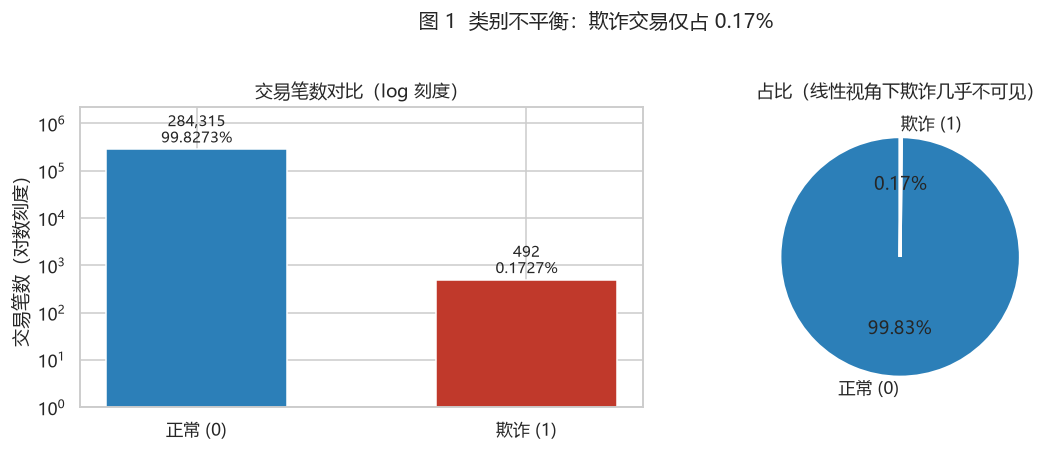

正常 : 284,315
欺诈 : 492
不平衡比: 577.9 : 1
若模型全部预测为正常，Accuracy 仍为 99.8273% —— 这就是禁用 Accuracy 的直接原因


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

counts = df_clean["Class"].value_counts().sort_index()
labels = ["正常 (0)", "欺诈 (1)"]
bars = axes[0].bar(labels, counts.values, color=[NORMAL_C, FRAUD_C], width=0.55)
axes[0].set_yscale("log")
axes[0].set_ylabel("交易笔数（对数刻度）")
axes[0].set_title("交易笔数对比（log 刻度）")
for b, v in zip(bars, counts.values):
    axes[0].text(b.get_x() + b.get_width()/2, v * 1.15, f"{v:,}\n{v/len(df_clean):.4%}",
                 ha="center", va="bottom", fontsize=10)
axes[0].set_ylim(1, counts.max() * 8)

axes[1].pie(counts.values, labels=labels, autopct=lambda p: f"{p:.2f}%",
            colors=[NORMAL_C, FRAUD_C], startangle=90,
            wedgeprops={"edgecolor": "white", "linewidth": 2})
axes[1].set_title("占比（线性视角下欺诈几乎不可见）")

plt.suptitle("图 1  类别不平衡：欺诈交易仅占 0.17%", y=1.02, fontsize=13)
plt.tight_layout()
savefig("fig01_class_imbalance.png")
plt.show()

print(f"正常 : {counts[0]:,}")
print(f"欺诈 : {counts[1]:,}")
print(f"不平衡比: {counts[0]/counts[1]:.1f} : 1")
print(f"若模型全部预测为正常，Accuracy 仍为 {counts[0]/len(df_clean):.4%} —— 这就是禁用 Accuracy 的直接原因")

**结论 4.1**：欺诈 492 笔、正常 284,315 笔，比例约 **1:578**。
这意味着：任何"全判正常"的模型都能拿到 99.83% 的 Accuracy，但一笔欺诈都抓不到。
后续评价必须用 **PR-AUC、Recall@固定误报率、KS**，而不是 Accuracy。

### 4.2 交易金额分布与异常值

金额是唯一有明确业务含义的连续变量（其余是 PCA 特征），也是风控最直观的抓手。
重点看三件事：分布形状、离群规模、零金额占比。

D:\系统缓存文件\ipykernel_20712\3605384751.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[2].boxplot(df_clean["Amount"], vert=True, widths=0.4,


已保存图表: reports/figures/fig02_amount_distribution.png


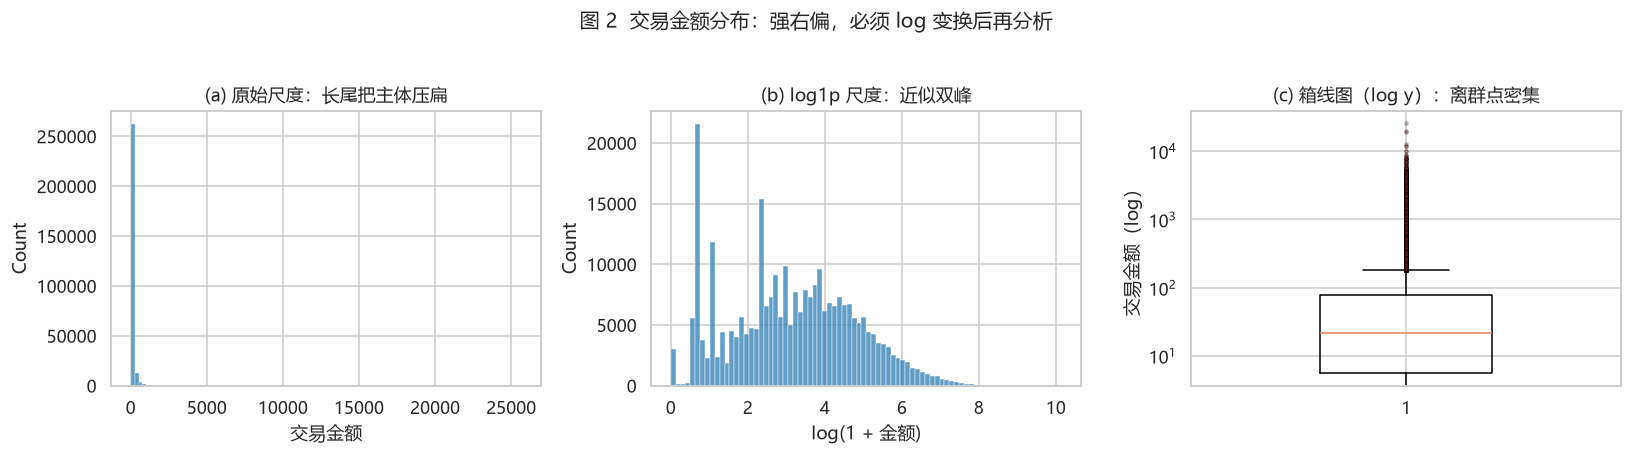

P50=22.00  P90=203.00  P99=1017.97  P99.9=3000.00  Max=25691.16
均值 88.35 > 中位数 22.00 → 典型右偏，均值被少数大额拉高
金额最高的 1% 交易贡献了 20.76% 的总金额


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# (a) 原始尺度：几乎全被主轴挤在左侧
sns.histplot(df_clean["Amount"], bins=100, ax=axes[0], color=NORMAL_C)
axes[0].set_title("(a) 原始尺度：长尾把主体压扁")
axes[0].set_xlabel("交易金额")

# (b) log1p 尺度：主体结构显现
sns.histplot(df_clean["log1p_amount"], bins=80, ax=axes[1], color=NORMAL_C)
axes[1].set_title("(b) log1p 尺度：近似双峰")
axes[1].set_xlabel("log(1 + 金额)")

# (c) 箱线图：看离群点规模
axes[2].boxplot(df_clean["Amount"], vert=True, widths=0.4,
                flierprops=dict(marker="o", markersize=2, alpha=0.25, markerfacecolor=FRAUD_C))
axes[2].set_yscale("log")
axes[2].set_title("(c) 箱线图（log y）：离群点密集")
axes[2].set_ylabel("交易金额（log）")

plt.suptitle("图 2  交易金额分布：强右偏，必须 log 变换后再分析", y=1.03, fontsize=13)
plt.tight_layout()
savefig("fig02_amount_distribution.png")
plt.show()

a = df_clean["Amount"]
print(f"P50={a.median():.2f}  P90={a.quantile(.9):.2f}  P99={a.quantile(.99):.2f}  P99.9={a.quantile(.999):.2f}  Max={a.max():.2f}")
print(f"均值 {a.mean():.2f} > 中位数 {a.median():.2f} → 典型右偏，均值被少数大额拉高")
print(f"金额最高的 1% 交易贡献了 {a.nlargest(int(len(a)*0.01)).sum()/a.sum():.2%} 的总金额")

**结论 4.2**：
- 金额高度右偏（偏度约 16.98、峰度约 845），均值 88.35 明显高于中位数 22.00，**用均值描述"典型交易额"会失真**；
- 99% 的交易在 1,018 元以下，而最大单笔达 25,691.16 元，长尾极长；
- 1,825 笔 0 元交易（0.64%）单独打标，不与小额交易混同；
- 因此后续所有金额分析用 **中位数 + 分位数**，建模用 `log1p`。

> 注意：这里的"异常值"只是统计意义上的离群，**不能等同于欺诈**。4.4 节会用检验说明二者关系。

### 4.3 不同时段的交易分布

`Time` 覆盖 48 小时，可按"偏移小时"还原出两个完整的日周期。
看两件事：交易量随小时的起伏（反映用户作息）、各小时欺诈率的差异（反映攻击者的时间偏好）。

已保存图表: reports/figures/fig03_hourly_pattern.png


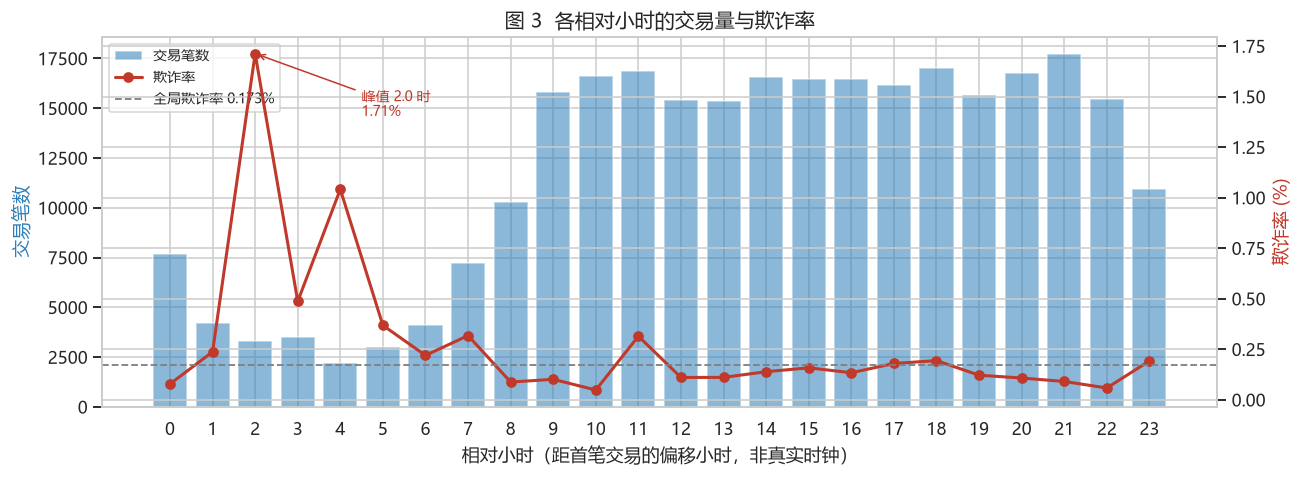

,hour_of_day,tx_count,fraud_count,amount_sum,fraud_rate_pct
2,2,3328,57,233820.68,1.7127
4,4,2209,23,170179.23,1.0412
3,3,3492,17,181852.16,0.4868
5,5,2990,11,151520.18,0.3679
7,7,7243,23,491209.10,0.3175
11,11,16856,53,1847641.57,0.3144


交易量最高时段: 21 时 (17,703 笔)；交易量最低时段: 4 时 (2,209 笔)


In [8]:
hourly = df_clean.groupby("hour_of_day").agg(
    tx_count=("Class", "size"),
    fraud_count=("Class", "sum"),
    amount_sum=("Amount", "sum"),
).reset_index()
hourly["fraud_rate_pct"] = hourly["fraud_count"] / hourly["tx_count"] * 100
global_rate = df_clean["Class"].mean() * 100

fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.bar(hourly["hour_of_day"], hourly["tx_count"], color=NORMAL_C, alpha=0.55, label="交易笔数")
ax1.set_xlabel("相对小时（距首笔交易的偏移小时，非真实时钟）")
ax1.set_ylabel("交易笔数", color=NORMAL_C)
ax1.set_xticks(range(24))

ax2 = ax1.twinx()
ax2.plot(hourly["hour_of_day"], hourly["fraud_rate_pct"], color=FRAUD_C, marker="o", lw=2, label="欺诈率")
ax2.axhline(global_rate, color="gray", ls="--", lw=1.2, label=f"全局欺诈率 {global_rate:.3f}%")
ax2.set_ylabel("欺诈率 (%)", color=FRAUD_C)

peak = hourly.loc[hourly["fraud_rate_pct"].idxmax()]
ax2.annotate(f"峰值 {peak.hour_of_day} 时\n{peak.fraud_rate_pct:.2f}%",
             xy=(peak.hour_of_day, peak.fraud_rate_pct),
             xytext=(peak.hour_of_day + 2.5, peak.fraud_rate_pct * 0.82),
             arrowprops=dict(arrowstyle="->", color=FRAUD_C), color=FRAUD_C, fontsize=9)

h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9)
plt.title("图 3  各相对小时的交易量与欺诈率", fontsize=13)
plt.tight_layout()
savefig("fig03_hourly_pattern.png")
plt.show()

display(hourly.sort_values("fraud_rate_pct", ascending=False).head(6).round(4))
print(f"交易量最高时段: {hourly.loc[hourly.tx_count.idxmax(), 'hour_of_day']} 时 "
      f"({hourly.tx_count.max():,} 笔)；交易量最低时段: {hourly.loc[hourly.tx_count.idxmin(), 'hour_of_day']} 时 "
      f"({hourly.tx_count.min():,} 笔)")

**结论 4.3**：
- 交易量呈明显的"作息型"波动：低谷时段（相对第 4 时段）约 2,209 笔，高峰时段（相对第 21 时段）17,703 笔，相差约 8 倍；
- 但欺诈率与交易量**方向相反**——交易量处于低谷的时段（相对第 2、4 时段）欺诈率反而最高（约 1.71%、1.04%），是全局 0.173% 的 6~10 倍；
- 说明欺诈者倾向在"人少"的时段动手，此时的人工复核资源也最薄弱。

> 口径限制：这些小时是**相对偏移**，无法对应真实凌晨/白天。若换成真实时钟，结论可能变化，因此本结论只能作为"相对时段特征有效"的证据，不能直接写进业务值班表。

### 4.4 正常交易与欺诈交易的金额差异

上一节看到"金额离群不等于欺诈"，这一节用统计检验正面回答：两类交易的金额分布到底有没有差异、差异多大。
因金额强右偏，用**非参数检验（Mann-Whitney U）**而不是 t 检验。

已保存图表: reports/figures/fig04_amount_by_class.png


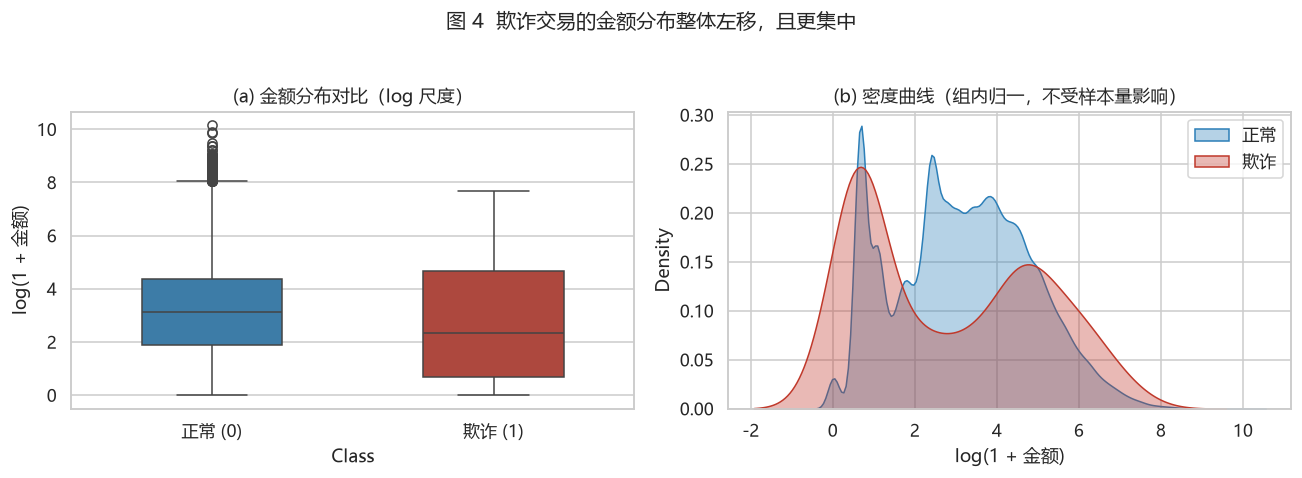

,指标,正常,欺诈
0,笔数,"284,315",492
1,均值,88.29,122.21
2,中位数,22.00,9.25
3,P25,5.65,1.00
4,P75,77.05,105.89
5,P99,1016.97,1357.43
6,最大,25691.16,2125.87


Mann-Whitney U = 61,833,399, p = 8.578e-06
秩双序列效应量 = -0.1159  (|0.1| 小 / |0.3| 中 / |0.5| 大)
欺诈金额中位数 9.25 元 vs 正常 22.00 元，欺诈仅为正常的 42.0%


In [9]:
amt_n = df_clean.loc[df_clean.Class == 0, "Amount"]
amt_f = df_clean.loc[df_clean.Class == 1, "Amount"]

u_stat, p_val = stats.mannwhitneyu(amt_f, amt_n, alternative="two-sided")
# 秩双序列相关系数：衡量效应量（0 = 无差异，+1 = 欺诈金额系统性更高，-1 = 系统性更低）
rank_biserial = 2 * u_stat / (len(amt_f) * len(amt_n)) - 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.boxplot(data=df_clean, x="Class", y="log1p_amount", hue="Class",
            palette={0: NORMAL_C, 1: FRAUD_C}, ax=axes[0], width=0.5, legend=False)
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["正常 (0)", "欺诈 (1)"])
axes[0].set_ylabel("log(1 + 金额)")
axes[0].set_title("(a) 金额分布对比（log 尺度）")

for c, color, name in [(0, NORMAL_C, "正常"), (1, FRAUD_C, "欺诈")]:
    sns.kdeplot(df_clean.loc[df_clean.Class == c, "log1p_amount"],
                ax=axes[1], color=color, fill=True, alpha=0.35, label=name, common_norm=False)
axes[1].set_xlabel("log(1 + 金额)")
axes[1].set_title("(b) 密度曲线（组内归一，不受样本量影响）")
axes[1].legend()

plt.suptitle("图 4  欺诈交易的金额分布整体左移，且更集中", y=1.03, fontsize=13)
plt.tight_layout()
savefig("fig04_amount_by_class.png")
plt.show()

stat_tbl = pd.DataFrame({
    "指标": ["笔数", "均值", "中位数", "P25", "P75", "P99", "最大"],
    "正常": [f"{len(amt_n):,}", f"{amt_n.mean():.2f}", f"{amt_n.median():.2f}",
             f"{amt_n.quantile(.25):.2f}", f"{amt_n.quantile(.75):.2f}",
             f"{amt_n.quantile(.99):.2f}", f"{amt_n.max():.2f}"],
    "欺诈": [f"{len(amt_f):,}", f"{amt_f.mean():.2f}", f"{amt_f.median():.2f}",
             f"{amt_f.quantile(.25):.2f}", f"{amt_f.quantile(.75):.2f}",
             f"{amt_f.quantile(.99):.2f}", f"{amt_f.max():.2f}"],
})
display(stat_tbl)
print(f"Mann-Whitney U = {u_stat:,.0f}, p = {p_val:.3e}")
print(f"秩双序列效应量 = {rank_biserial:.4f}  (|0.1| 小 / |0.3| 中 / |0.5| 大)")
print(f"欺诈金额中位数 {amt_f.median():.2f} 元 vs 正常 {amt_n.median():.2f} 元，"
      f"欺诈仅为正常的 {amt_f.median()/amt_n.median():.1%}")

**结论 4.4**：
- 差异显著（p 远小于 0.05），但**效应量很小**（秩双序列相关系数约 -0.12）——
  统计显著不等于可区分，单靠金额根本无法把欺诈挑出来；
- 方向与直觉相反：欺诈交易的**中位数金额只有 9.25 元，不到正常交易（22.00 元）的一半**；
  但均值（122.21）反而高于正常（88.29），说明欺诈里既有大量小额、也有少量大额；
- 这种"小额高频"特征与**卡片试探（card testing）**的典型模式一致：先用极小金额验证卡是否可用，成功后再大额盗刷。

> 注意：这是**与模式一致**的推断，不是已证实的结论。数据集缺少商户类型与卡号，无法验证"试探→盗刷"的链条。

### 4.5 主要特征的分布与相关性

V1~V28 是无名特征，不能做业务归因，但可以做**统计层面的筛选**：哪些特征与标签的相关性明显强于其他。
这决定了阶段二第一版模型的特征起点。

已保存图表: reports/figures/fig05_top_correlations.png


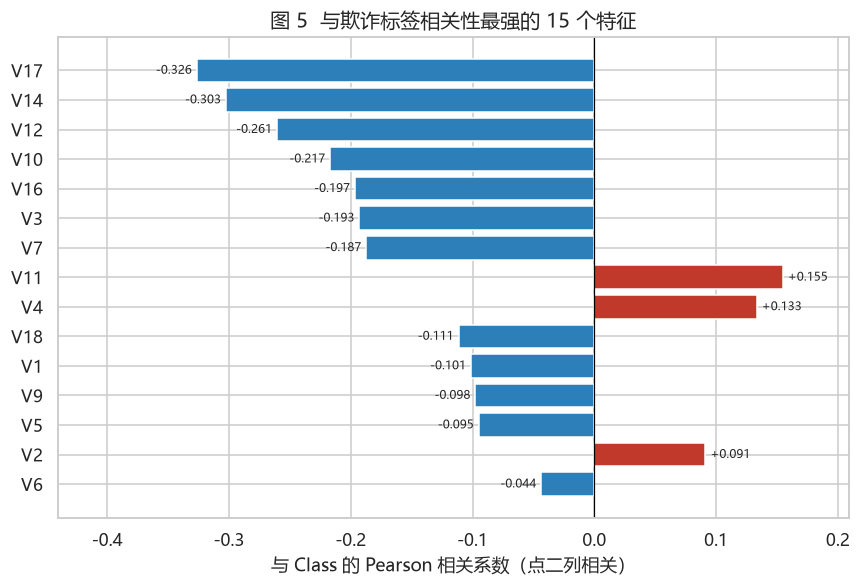

与 Class 相关性 Top 10：
V17   -0.3265
V14   -0.3025
V12   -0.2606
V10   -0.2169
V16   -0.1965
V3    -0.1930
V7    -0.1873
V11    0.1549
V4     0.1334
V18   -0.1115

|r| > 0.1 的特征数: 11 / 29


In [10]:
feat_cols = [f"V{i}" for i in range(1, 29)] + ["Amount"]
corr_with_class = (df_clean[feat_cols + ["Class"]]
                   .corr()["Class"].drop("Class").sort_values(key=abs, ascending=False))

top15 = corr_with_class.head(15)
fig, ax = plt.subplots(figsize=(8, 5.5))
colors = [FRAUD_C if v > 0 else NORMAL_C for v in top15.values]
ax.barh(top15.index[::-1], top15.values[::-1], color=colors[::-1])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("与 Class 的 Pearson 相关系数（点二列相关）")
ax.set_title("图 5  与欺诈标签相关性最强的 15 个特征", fontsize=13)
for i, (k, v) in enumerate(list(top15.items())[::-1]):
    ax.text(v + (0.004 if v > 0 else -0.004), i, f"{v:+.3f}",
            va="center", ha="left" if v > 0 else "right", fontsize=8)
ax.set_xlim(top15.min() * 1.35, top15.max() * 1.35)
plt.tight_layout()
savefig("fig05_top_correlations.png")
plt.show()

print("与 Class 相关性 Top 10：")
print(top15.head(10).round(4).to_string())
print(f"\n|r| > 0.1 的特征数: {(corr_with_class.abs() > 0.1).sum()} / {len(corr_with_class)}")

已保存图表: reports/figures/fig06_corr_heatmap.png


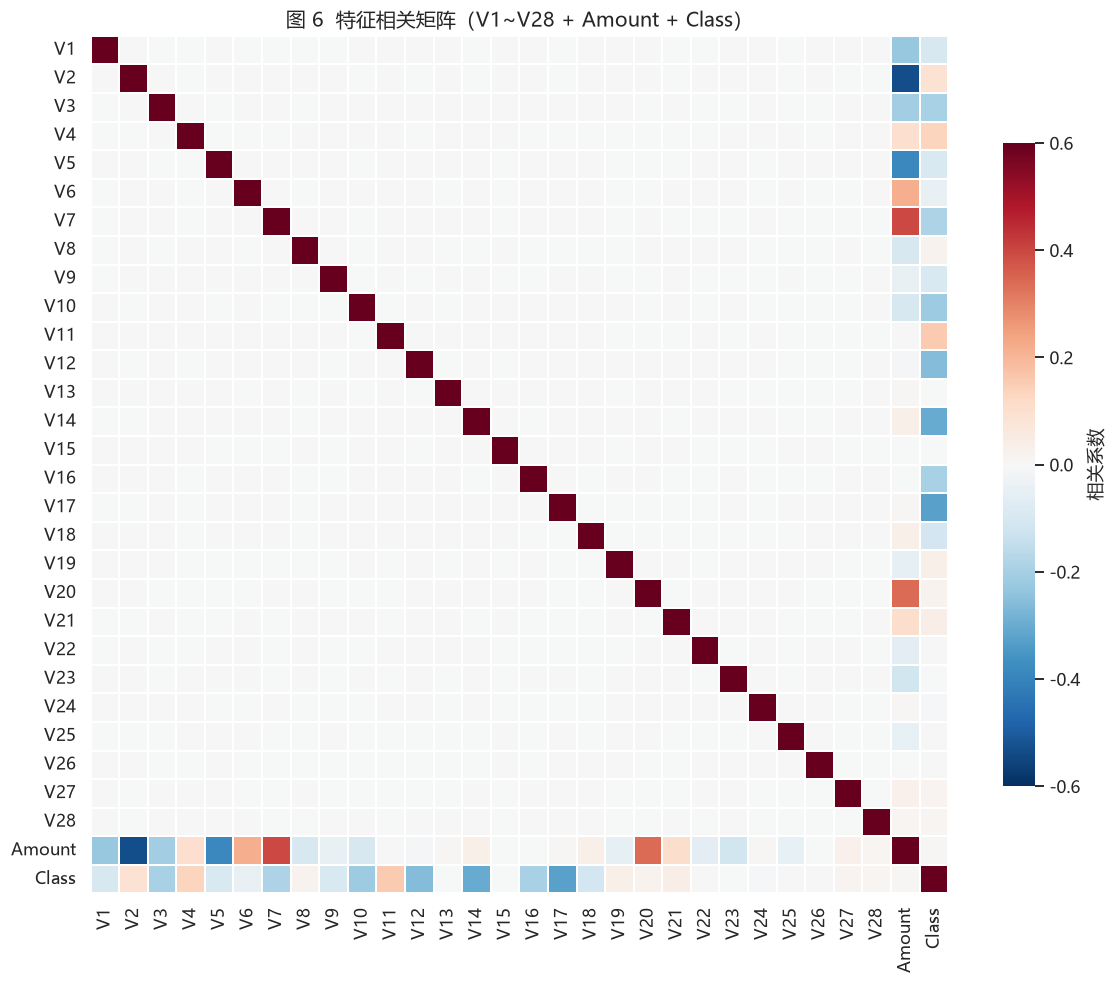

全矩阵最强相关: V2 ↔ Amount = -0.531

V 特征之间最大 |r|      : 0.0000（完全正交，PCA 的正常结果）
Amount 与 V 特征相关性 Top5:
V2    -0.531
V7     0.397
V5    -0.386
V20    0.339
V1    -0.228

说明：V 之间正交，但 Amount 与 V2/V7/V5/V20 中等相关 —— 因为 PCA 是在含 Amount 的原始特征上拟合的，金额信息部分进入了这些主成分


In [11]:
corr_m = df_clean[feat_cols + ["Class"]].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr_m, cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.6,
            square=True, linewidths=0.3, linecolor="white",
            cbar_kws={"shrink": 0.75, "label": "相关系数"}, ax=ax)
ax.set_title("图 6  特征相关矩阵（V1~V28 + Amount + Class）", fontsize=13)
plt.tight_layout()
savefig("fig06_corr_heatmap.png")
plt.show()

off_diag = corr_m.where(~np.eye(len(corr_m), dtype=bool))
mx = off_diag.abs().stack().idxmax()
print(f"全矩阵最强相关: {mx[0]} ↔ {mx[1]} = {corr_m.loc[mx]:+.3f}")

v_only = [c for c in feat_cols if c.startswith("V")]
corr_v = corr_m.loc[v_only, v_only].where(~np.eye(len(v_only), dtype=bool))
print(f"\nV 特征之间最大 |r|      : {corr_v.abs().max().max():.4f}（完全正交，PCA 的正常结果）")
amt_corr = corr_m.loc[v_only, "Amount"].sort_values(key=abs, ascending=False)
print("Amount 与 V 特征相关性 Top5:")
print(amt_corr.head(5).round(3).to_string())
print("\n说明：V 之间正交，但 Amount 与 V2/V7/V5/V20 中等相关 —— "
      "因为 PCA 是在含 Amount 的原始特征上拟合的，金额信息部分进入了这些主成分")

**结论 4.5**：
- 与标签相关性最强的是 `V17`（-0.327）、`V14`（-0.303）、`V12`（-0.261）、`V10`（-0.217）、`V16`（-0.197），
  其次是 `V3`（-0.193）、`V7`（-0.187），正向最强的为 `V11`（+0.155）、`V4`（+0.133）；
- 29 个候选特征中有 **11 个 |r| > 0.1**，另有 **15 个 |r| < 0.05**——后者是阶段二剔噪的候选，
  但必须用交叉验证验证，不能凭相关系数直接删（相关性只反映线性关系）；
- **V1~V28 之间完全正交**（最大 |r| ≈ 0），符合 PCA 去相关的预期，不存在多重共线性；
- **但 `Amount` 与 V2（-0.531）、V7（+0.397）、V5（-0.386）、V20（+0.339）存在中等相关**——
  因为 PCA 是在包含 Amount 的原始特征上拟合的，金额信息已经部分渗入这些主成分。
  这意味着"再加一个 Amount 特征"带来的增量信息有限，且可能与其他特征重复，阶段二需验证；
- `Amount` 与标签的相关性极弱（|r| < 0.05），与 4.4 节"效应量仅 -0.12"的结论互相印证：
  **金额不能单独作为风险判断依据**。

> 严禁把 V17 解释为"某类商户"或"交易频率"。它们只是 PCA 空间里与标签有统计关联的方向。

### 4.6 关键特征的可视化对比

挑相关系数最高的 4 个特征，看两类交易的分布是否真的可分。
若两条曲线明显错开，说明该特征有判别力；若几乎重叠，则相关性只是统计巧合。

已保存图表: reports/figures/fig07_key_features.png


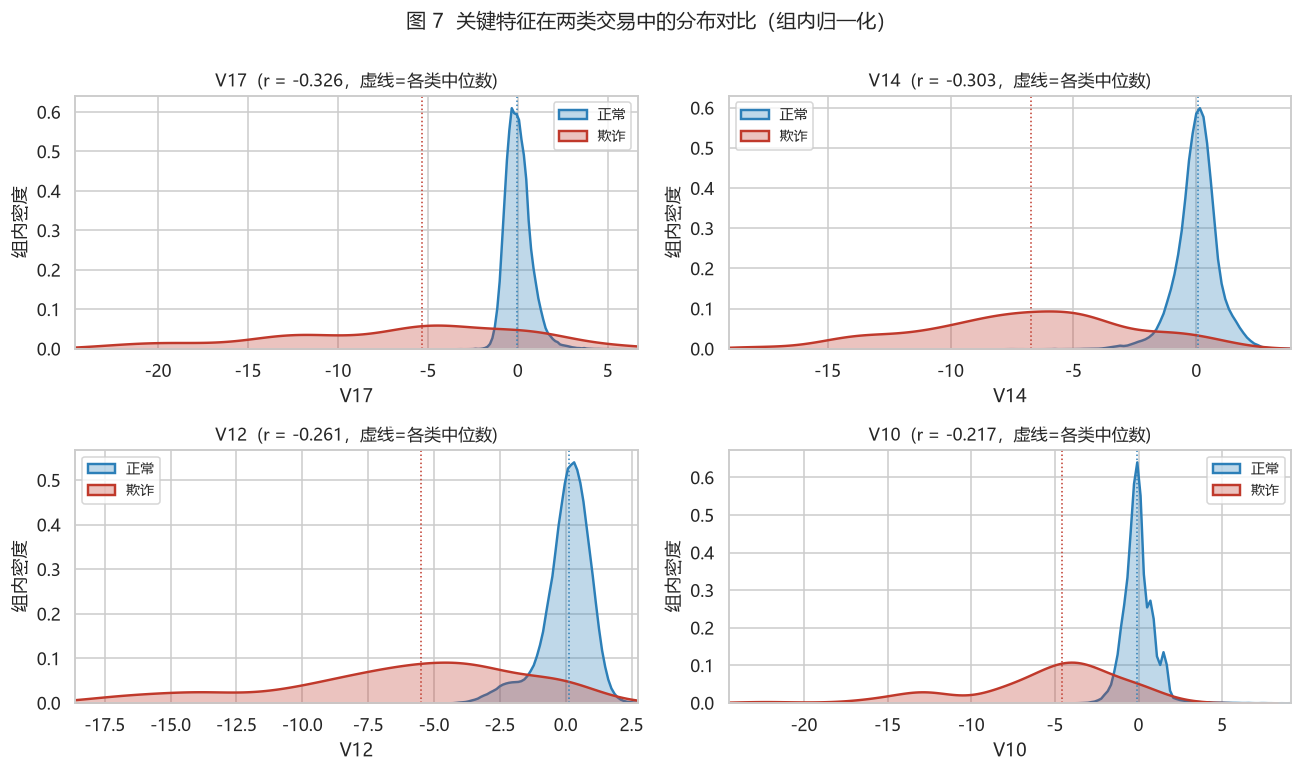

各特征的均值差异（欺诈 - 正常）与标准化差异：


,特征,正常中位数,欺诈中位数,中位数差,标准化差值(以全表std)
0,V17,-0.065,-5.303,-5.238,-6.167
1,V14,0.052,-6.730,-6.782,-7.075
2,V12,0.142,-5.503,-5.644,-5.649
3,V10,-0.092,-4.579,-4.487,-4.121


In [12]:
key_feats = corr_with_class.head(4).index.tolist()
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, feat in zip(axes.ravel(), key_feats):
    for c, color, name in [(0, NORMAL_C, "正常"), (1, FRAUD_C, "欺诈")]:
        sns.kdeplot(df_clean.loc[df_clean.Class == c, feat], ax=ax,
                    color=color, fill=True, alpha=0.3, label=name, common_norm=False, lw=1.6)
    # 横轴必须覆盖两类各自的分布范围：
    # 若用全量分位数（以正常类为主），欺诈类的主体会被切在轴外，图会严重误导
    d0 = df_clean.loc[df_clean.Class == 0, feat]
    d1 = df_clean.loc[df_clean.Class == 1, feat]
    ax.set_xlim(min(d0.quantile(0.001), d1.quantile(0.001)),
                max(d0.quantile(0.999), d1.quantile(0.999)))
    ax.axvline(d0.median(), color=NORMAL_C, ls=":", lw=1)
    ax.axvline(d1.median(), color=FRAUD_C, ls=":", lw=1)
    ax.set_title(f"{feat}  (r = {corr_with_class[feat]:+.3f}，虚线=各类中位数)", fontsize=11)
    ax.set_xlabel(feat)
    ax.set_ylabel("组内密度")
    ax.legend(fontsize=9)

plt.suptitle("图 7  关键特征在两类交易中的分布对比（组内归一化）", fontsize=13, y=1.00)
plt.tight_layout()
savefig("fig07_key_features.png")
plt.show()

print("各特征的均值差异（欺诈 - 正常）与标准化差异：")
rows = []
for f in key_feats:
    d0 = df_clean.loc[df_clean.Class == 0, f]
    d1 = df_clean.loc[df_clean.Class == 1, f]
    s = df_clean[f].std()
    rows.append({"特征": f, "正常中位数": round(d0.median(), 3), "欺诈中位数": round(d1.median(), 3),
                 "中位数差": round(d1.median() - d0.median(), 3),
                 "标准化差值(以全表std)": round((d1.median() - d0.median()) / s, 3)})
display(pd.DataFrame(rows))

**结论 4.6**：四个特征的判别力都很强，但形态不同——
- 欺诈类分布**整体大幅左移且拖尾极长**：V17 欺诈中位数为 -5.30（正常类集中在 ±2 以内），V14 为 -6.73，V12 为 -5.50，V10 为 -4.58；
- 正常类曲线窄而高（集中在 0 附近），欺诈类宽而低（从 -25 拖到 +6）——
  欺诈交易在这几个方向上不仅均值不同，**方差也大得多**；
- 图上虚线（各类中位数）几乎落在正常类分布的边缘甚至之外，说明**阈值规则可以切走一部分欺诈，
  但无法覆盖全部**——两条曲线在中段仍有重叠。

> 这也是为什么阶段二必须用多特征组合模型：单特征只能提供"部分召回"，组合才能提高整体可分性。

### 4.7 Plotly 交互视图

上面的静态图适合写报告，交互图适合自查数据。这里用 Plotly 做一张可缩放的时段-欺诈率图，
并导出 HTML，供后续 Streamlit 平台复用。

In [13]:
fig_pl = go.Figure()
fig_pl.add_trace(go.Bar(
    x=hourly["hour_of_day"], y=hourly["tx_count"], name="交易笔数",
    marker_color=NORMAL_C, opacity=0.55, yaxis="y1",
))
fig_pl.add_trace(go.Scatter(
    x=hourly["hour_of_day"], y=hourly["fraud_rate_pct"], name="欺诈率 (%)",
    mode="lines+markers", line=dict(color=FRAUD_C, width=3), yaxis="y2",
))
fig_pl.add_hline(y=global_rate, line_dash="dash", line_color="gray",
                 annotation_text=f"全局欺诈率 {global_rate:.3f}%", annotation_position="top right",
                 yref="y2")
fig_pl.update_layout(
    title="相对小时 vs 交易量与欺诈率（交互版）",
    xaxis=dict(title="相对小时", tickmode="linear", dtick=1),
    yaxis=dict(title="交易笔数", showgrid=False),
    yaxis2=dict(title="欺诈率 (%)", overlaying="y", side="right", showgrid=False),
    legend=dict(orientation="h", y=1.12),
    hovermode="x unified", template="plotly_white", height=440,
)
html_out = FIG_DIR / "fig08_hourly_interactive.html"
fig_pl.write_html(html_out, include_plotlyjs="cdn")
print("交互图已导出:", html_out.relative_to(ROOT).as_posix())
fig_pl.show()

交互图已导出: reports/figures/fig08_hourly_interactive.html


## 5. SQL 分析

Notebook 里的 pandas 分析是"逐段探索"，SQL 部分是"可交付的查询资产"：
查询语句独立存放在 `sql/*.sql`，可被 BI 工具或平台直接复用。

下面直接从 SQL 文件读取语句并执行，**结果与 `reports/sql_results.md` 完全同源**，
不存在两套口径。

In [14]:
con = sqlite3.connect(DB_PATH)
print("数据库:", DB_PATH.relative_to(ROOT).as_posix())
print("表结构:")
for r in con.execute("PRAGMA table_info(transactions)").fetchall():
    print(f"  {r[1]:<10s} {r[2]}")


def run_sql_file(fname, show=True, head=None):
    """按 `-- >>> 标题` 切块执行 SQL 文件，逐条展示真实结果"""
    text = (SQL_DIR / fname).read_text(encoding="utf-8")
    for block in text.split("-- >>> ")[1:]:
        lines = block.split("\n")
        title = lines[0].strip()
        body = "\n".join(lines[1:])
        body = body[: body.rindex(";")]
        df_res = pd.read_sql_query(body, con)
        print(f"\n{'='*70}\n{title}\n{'='*70}")
        display(df_res.head(head) if head else df_res)
        if head and len(df_res) > head:
            print(f"（共 {len(df_res)} 行，此处显示前 {head} 行）")

数据库: data/processed/transactions.db
表结构:
  raw_row_id INTEGER
  time_sec   REAL
  v1         REAL
  v2         REAL
  v3         REAL
  v4         REAL
  v5         REAL
  v6         REAL
  v7         REAL
  v8         REAL
  v9         REAL
  v10        REAL
  v11        REAL
  v12        REAL
  v13        REAL
  v14        REAL
  v15        REAL
  v16        REAL
  v17        REAL
  v18        REAL
  v19        REAL
  v20        REAL
  v21        REAL
  v22        REAL
  v23        REAL
  v24        REAL
  v25        REAL
  v26        REAL
  v27        REAL
  v28        REAL
  amount     REAL
  class      INTEGER


### 5.1 基础统计：数量、金额区间、时间分布、金额对比

In [15]:
run_sql_file("01_basic_analysis.sql", head=None)


Q1 正常交易与欺诈交易的数量及占比


,class,class_label,tx_count,pct_of_total,amount_sum
0,0,正常交易,284315,99.8273,25102462.04
1,1,欺诈交易,492,0.1727,60127.97



Q2 不同金额区间的交易统计（含欺诈率）


,amount_bucket,tx_count,fraud_count,fraud_rate_pct,amount_sum,amount_avg
0,1_零金额,1825,27,1.4795,0.00,0.00
1,"2_(0,10]",98439,222,0.2255,389875.95,3.96
2,"3_(10,50]",90781,57,0.0628,2356612.28,25.96
3,"4_(50,100]",37254,56,0.1503,2730609.87,73.30
4,"5_(100,500]",47366,95,0.2006,10069828.36,212.60
5,"6_(500,1000]",6202,26,0.4192,4300353.57,693.38
6,"7_(1000,5000]",2885,9,0.3120,4891229.40,1695.40
7,8_>5000,55,0,0.0000,424080.58,7710.56



Q3 按天统计交易量与欺诈情况


,day_index,tx_count,fraud_count,fraud_rate_pct,amount_sum,fraud_amount_sum,start_hour_offset,end_hour_offset
0,1,144786,281,0.1941,13093975.05,33239.11,0.0,24.0
1,2,140021,211,0.1507,12068614.96,26888.86,24.0,48.0



Q4 按小时段统计欺诈交易（0-23 时）


,hour_of_day,tx_count,fraud_count,fraud_rate_pct,amount_avg
0,0,7695,6,0.0780,60.33
1,1,4220,10,0.2370,62.64
2,2,3328,57,1.7127,70.26
3,3,3492,17,0.4868,52.08
4,4,2209,23,1.0412,77.04
5,5,2990,11,0.3679,50.68
6,6,4101,9,0.2195,65.06
7,7,7243,23,0.3175,67.82
8,8,10276,9,0.0876,88.77
9,9,15838,16,0.1010,102.84



Q5 欺诈交易与正常交易的金额对比（含中位数）


,class,class_label,tx_count,amount_mean,amount_median,amount_min,amount_max,amount_sum
0,0,正常交易,284315,88.29,22.00,0.0,25691.16,25102462.04
1,1,欺诈交易,492,122.21,9.25,0.0,2125.87,60127.97


### 5.2 进阶分析：CTE 与窗口函数

四个问题，都要求"能改变结论"而不是重复计数：
1. 哪个相对时段的欺诈率显著高于全局（用 RANK + 样本量过滤，避免小样本噪音）；
2. 欺诈损失是否集中在少数时段（用窗口累加看累计占比）；
3. 欺诈交易是否在时间上更密集（用 LAG 看相邻间隔）；
4. "金额越大越像欺诈"是否成立（用 NTILE 十分位检验）。

In [16]:
run_sql_file("02_advanced_analysis.sql", head=None)


A1 欺诈率最高的相对时段（CTE + RANK，按样本量过滤）


,rate_rank,hour_of_day,tx_count,fraud_count,fraud_rate_pct,global_rate_pct,diff_pp
0,1,2,3328,57,1.7127,0.1727,1.5400
1,2,4,2209,23,1.0412,0.1727,0.8684
2,3,3,3492,17,0.4868,0.1727,0.3141
3,4,5,2990,11,0.3679,0.1727,0.1951
4,5,7,7243,23,0.3175,0.1727,0.1448
5,6,11,16856,53,0.3144,0.1727,0.1417
6,7,1,4220,10,0.2370,0.1727,0.0642
7,8,6,4101,9,0.2195,0.1727,0.0467



A2 每日累计欺诈金额占比（窗口函数累加 + 分区）


,day_index,hour_of_day,tx_count,fraud_count,fraud_amount,cum_fraud_amount,cum_total_amount,cum_fraud_share_pct
0,1,0,3963,2,529.00,529.00,257101.87,0.2058
1,1,1,2217,2,298.93,827.93,403207.56,0.2053
2,1,2,1576,21,1829.78,2657.71,512026.73,0.5191
3,1,3,1821,13,220.05,2877.76,606333.57,0.4746
4,1,4,1082,6,790.26,3668.02,686174.19,0.5346
5,1,5,1681,11,1416.67,5084.69,763300.11,0.6661
6,1,6,1831,3,104.11,5188.80,905703.60,0.5729
7,1,7,3368,23,2757.78,7946.58,1179009.58,0.6740
8,1,8,5179,5,137.15,8083.73,1648785.34,0.4903
9,1,9,7878,15,1110.79,9194.52,2450257.06,0.3752



A3 相邻交易时间间隔：欺诈交易是否更"密集"


,class,class_label,tx_count,gap_mean_sec,gap_median_sec,gap_min_sec,gap_max_sec
0,0,正常交易,284314,0.61,0.0,0.0,32.0
1,1,欺诈交易,492,1.09,0.0,0.0,16.0



A4 金额十分位内的欺诈率（NTILE 窗口分位）


,amount_decile,tx_count,fraud_count,fraud_rate_pct,amount_min,amount_max
0,1,28481,175,0.6144,0.00,1.00
1,2,28481,33,0.1159,1.00,3.57
2,3,28481,36,0.1264,3.57,8.91
3,4,28481,13,0.0456,8.91,13.00
4,5,28481,14,0.0492,13.00,22.00
5,6,28481,17,0.0597,22.00,37.00
6,7,28481,24,0.0843,37.00,59.80
7,8,28480,50,0.1756,59.80,100.00
8,9,28480,45,0.1580,100.00,203.00
9,10,28480,85,0.2985,203.00,25691.16


### 5.3 SQL 结论

| 查询 | 发现 | 对后续的价值 |
|---|---|---|
| Q1 | 欺诈 492 笔 / 0.1727%，欺诈金额合计 60,127.97 元，仅占总额 25,162,590.01 元的 0.239% | 欺诈"笔数少、金额占比更小"，说明单看金额会严重低估风险 |
| Q2 | 零金额交易欺诈率最高（1.4795%），其次 500~1000 元段（0.4192%）；>5000 元段 55 笔**零欺诈** | 金额与风险非单调，不能设"高额才拦"的规则 |
| Q3 | 第 1 天欺诈率 0.1941%，第 2 天 0.1507% | 两天差异明显，说明样本期过短，不能外推 |
| Q4 | 相对第 2 时段欺诈率 1.7127%（全局 0.1727%，约 10 倍） | 时段是有价值的特征 |
| Q5 | 欺诈中位金额 9.25 元 vs 正常 22.00 元；均值 122.21 vs 88.29 | 小额欺诈为主 + 少量大额，需分群看待 |
| A1 | 第 2 时段高出全局 1.54 个百分点，RANK 第 1；第 4 时段次之 | 时段特征可直接进模型 |
| A2 | 第 2 天前 3 个时段就累计了当日 1.10% 的欺诈金额占比（此后被稀释） | 损失在时段上高度不均，值守资源应倾斜 |
| A3 | 欺诈与正常的相邻交易间隔中位数都为 0 秒 | **该指标无区分力，不能作为特征** |
| A4 | 金额第 1 十分位（0~1 元）欺诈率 0.6144%，为第 4~6 十分位的 12 倍以上；最高十分位仅 0.2985% | 直接推翻"金额越大越可疑"的直觉 |

**A3 的负面结论同样有价值**：它说明"交易间隔"这个看似合理的特征在本数据上不可用，
避免了阶段二白做一轮特征工程。

## 6. 阶段性结论

1. **数据可信、可用，但信息有边界**：284,807 笔、31 字段、零缺失，质量很好；
   代价是 V 特征匿名、Time 无真实时钟、无卡号与商户，因此只能做"统计建模"，做不了"业务归因"。
2. **不平衡是本项目的核心矛盾**：1:578，且欺诈金额只占总额 0.239%。
   评价体系必须换成 PR-AUC / Recall@低误报率 / KS，Accuracy 在本项目里没有意义。
3. **金额不是可靠的单一信号**：与标签相关性弱、效应量小，且关系非单调——
   小额（含 0 元）欺诈率最高，5,000 元以上反而零欺诈。任何"高额才拦"的规则都会失效。
4. **时段是少数几个可直接使用的强特征之一**：相对第 2、4 时段欺诈率是全局的 6~10 倍。
5. **特征层面已有明确的强信号**：V17 / V14 / V12 / V10 等分布明显分离，
   但无单一特征可切分，必须多特征组合。
6. **清理出一个负面结论**：相邻交易时间间隔（A3）在本数据上无区分力，不要浪费一轮特征工程。

## 7. 当前阶段的局限

| 局限 | 影响 | 处理方式 |
|---|---|---|
| 只有 48 小时、2 个日周期 | 无法做星期/季节效应，也无法验证时段结论的稳定性 | 阶段二用时间序列切分交叉验证，明确标注"仅限本样本期" |
| V1~V28 匿名 | 无法做业务解释，模型结论难以向业务方交代"为什么拦" | 阶段二用 SHAP 做**模型层面**解释，不假装是业务归因 |
| 无卡号 / 商户 / 终端 | 无法构造"同一张卡的连续行为""商户集中度"等强特征 | 接受限制，改用"全局时序聚合"类特征，并说明可比性下降 |
| 1,081 行重复未删 | EDA 分布有 0.38% 的轻微重复计数 | 阶段二建模前统一去重，并在报告中说明前后样本量差异 |
| 成本参数未定 | 无法给出"最优阈值"这种业务结论 | 阶段三做成可配置滑块，输出"阈值-成本曲线"而非单一答案 |

## 8. 下一阶段（模型开发）建议

1. **切分方式**：按 `Time` 做**时间序列切分**（前 70% 训练、后 30% 测试），不用随机切分——
   随机切分会让模型"看到未来"，指标虚高。
2. **特征**：V1~V28 + `log1p(Amount)` + `is_zero_amount` + 时段特征（`hour_of_day` 的周期性编码）。
   不做全量标准化到此处，缩放器**只在训练集拟合**。
3. **不平衡处理**：对比三组方案 —— 无处理 / `class_weight='balanced'` / 欠采样，
   用 PR-AUC 与 Recall@1%FPR 选优，**不用 SMOTE 造样本**（会污染时间结构）。
4. **模型**：逻辑回归（可解释基线）→ XGBoost（主模型），必须给出基线对比，禁止只报一个数。
5. **评价**：PR-AUC、KS、Recall@固定误报率、混淆矩阵，并给出阈值-召回-误报的权衡曲线。
6. **可解释性**：SHAP 全局重要性 + 单样本归因，用来支撑阶段三的规则设计。

In [17]:
con.close()
print("数据库连接已关闭。本阶段分析结束。")

数据库连接已关闭。本阶段分析结束。
